# Figure 2: drug vs untreated z-scores in A375 and HT-29

Compares guide z-scores (each drug vs untreated) between A375 and HT-29 cells for Pictilisib,
Linsitinib and SCH772984. Hit guides are coloured by gene and labelled with their amino-acid edits.

**Folder layout**

```
├── Fig2_Zscores.ipynb
├── data/
│   ├── SupplementaryTable4.xlsx    drug vs untreated z-scores and hit calls per guide
│   └── EG-guides.xlsx              guide annotations, including amino-acid edits [add source]
└── output/
    └── figures/
        └── plot3panels.png
```

## Setup

In [29]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

data_dir = Path("data")
figure_dir = Path("output") / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)
plt.rcParams["figure.dpi"] = 150

## Load z-scores

In [2]:
drug_vs_untreated = pd.read_excel(data_dir / "SupplementaryTable4.xlsx")

# Keep only the z-scores and hit calls
cols_to_drop = [col for col in drug_vs_untreated.columns if col.endswith(("_pval", "_fdr"))]
drug_vs_untreated = drug_vs_untreated.drop(columns=cols_to_drop + ["Editor"])
drug_vs_untreated.head()

,Guide,Gene,A375_PIC_Control,A375_SCH_Control,A375_LIN_Control,HT29_PIC_Control,HT29_SCH_Control,HT29_LIN_Control,A375_PIC_Control_hit,A375_SCH_Control_hit,A375_LIN_Control_hit,HT29_PIC_Control_hit,HT29_SCH_Control_hit,HT29_LIN_Control_hit
0,AAAAAACATCGTAGTAGCAG,RICTOR,0.274277,-0.283221,-1.161903,-0.148506,0.303898,0.001678,non-hit,non-hit,non-hit,non-hit,non-hit,non-hit
1,AAAAAACTCAACAGCAGTGA,NRAS,0.399691,0.193242,0.268929,0.740149,-0.239436,-0.463867,non-hit,non-hit,non-hit,non-hit,non-hit,non-hit
2,AAAAAACTGGCCAGGTGAGC,PIK3CB,0.399178,-0.386660,0.370558,1.166385,-0.461033,-0.317750,non-hit,non-hit,non-hit,non-hit,non-hit,non-hit
3,AAAAAACTGTTTGGGACCTC,EGFR,-0.801011,-0.872166,0.570972,0.080902,-0.113501,-0.395299,non-hit,non-hit,non-hit,non-hit,non-hit,non-hit
4,AAAAAAGTTTCTTCCTGTAT,PIK3CB,-0.535056,0.759443,0.252670,-0.104681,-0.186513,-0.158499,non-hit,non-hit,non-hit,non-hit,non-hit,non-hit


## Reshape to one row per guide per drug

In [3]:
# Rename columns so drug is a suffix, cell line/metric is a prefix
rename_map = {}
for drug in ['PIC', 'SCH', 'LIN']:
    rename_map[f'A375_{drug}_Control'] = f'A375_z-score_{drug}'
    rename_map[f'HT29_{drug}_Control'] = f'HT29_z-score_{drug}'
    rename_map[f'A375_{drug}_Control_hit'] = f'A375_Hit_{drug}'
    rename_map[f'HT29_{drug}_Control_hit'] = f'HT29_Hit_{drug}'

df_renamed = drug_vs_untreated.rename(columns=rename_map)

drug_vs_untreated_long = pd.wide_to_long(
    df_renamed,
    stubnames=['A375_z-score', 'HT29_z-score', 'A375_Hit', 'HT29_Hit'],
    i=['Guide', 'Gene'],
    j='Drug',
    sep='_',
    suffix=r'\w+'
).reset_index()

# Sort by guide, then drug
drug_vs_untreated_long = drug_vs_untreated_long.sort_values(['Guide', 'Drug']).reset_index(drop=True)
drug_vs_untreated_long.head()

,Guide,Gene,Drug,A375_z-score,HT29_z-score,A375_Hit,HT29_Hit
0,AAAAAACATCGTAGTAGCAG,RICTOR,LIN,-1.161903,0.001678,non-hit,non-hit
1,AAAAAACATCGTAGTAGCAG,RICTOR,PIC,0.274277,-0.148506,non-hit,non-hit
2,AAAAAACATCGTAGTAGCAG,RICTOR,SCH,-0.283221,0.303898,non-hit,non-hit
3,AAAAAACTCAACAGCAGTGA,NRAS,LIN,0.268929,-0.463867,non-hit,non-hit
4,AAAAAACTCAACAGCAGTGA,NRAS,PIC,0.399691,0.740149,non-hit,non-hit


## Add amino-acid edits for each guide

In [4]:
eg_guides = pd.read_excel(data_dir / "EG-guides.xlsx")
eg_guides_cbe = eg_guides[eg_guides["Edit Type"] == "C-T"]

drug_vs_untreated_long = drug_vs_untreated_long.merge(
    eg_guides_cbe[['sgRNA Sequence', 'Target Gene Symbol', 'Amino Acid Edits']],
    left_on=["Guide", "Gene"],
    right_on=["sgRNA Sequence", "Target Gene Symbol"],
    how="left",
    indicator=True
)

# Check match counts: unmatched guides should only be controls
print(drug_vs_untreated_long['_merge'].value_counts())
unmatched = drug_vs_untreated_long[drug_vs_untreated_long['_merge'] == 'left_only']
unmatched['Gene'].value_counts()

_merge
both          115212
left_only       3216
right_only         0
Name: count, dtype: int64


Gene
Intergenic control        3000
Panlethal splice donor     216
Name: count, dtype: int64

## Split by drug and separate hits from non-hits

In [5]:
# Separate dataframe for each drug
df_lin = drug_vs_untreated_long[drug_vs_untreated_long['Drug'] == 'LIN'].reset_index(drop=True)
df_pic = drug_vs_untreated_long[drug_vs_untreated_long['Drug'] == 'PIC'].reset_index(drop=True)
df_sch = drug_vs_untreated_long[drug_vs_untreated_long['Drug'] == 'SCH'].reset_index(drop=True)

dfs    = [df_pic, df_lin, df_sch]
titles = ['Pictilisib', 'Linsitinib', 'SCH772984']

# A guide is a hit if it is a positive hit in either cell line
hits_list = []
nonhits_list = []

for df, title in zip(dfs, titles):
    mask = (df['A375_Hit'] == 'positive') | (df['HT29_Hit'] == 'positive')
    h  = df[mask].copy()
    h['Drug'] = title
    hits_list.append(h)

    nh = df[~mask].copy()
    nh['Drug'] = title
    nonhits_list.append(nh)

df_all_hits    = pd.concat(hits_list).sample(frac=1, random_state=42).reset_index(drop=True)
df_all_nonhits = pd.concat(nonhits_list)

# Full per-drug data, for the correlation in each panel
df_by_drug = dict(zip(titles, dfs))

## Plot settings
Colours, axis limits, font sizes and label positions

In [6]:
# Gene colours
gene_color_map = {
    'PIK3CA':  '#1a7a3c',
    'PTEN':    '#3fae5a',
    'AKT1':    '#7bc97e',
    'MTOR':    '#b8e3ab',
    'MAP2K1':  '#e0791e',
    'MAP2K2':  '#f2a541',
    'MAPK1':   '#e8c468',
    'MAPK3':   '#f0dca0',
    'PGD':     '#7b2d8e',
    'PKM':     '#c9a3d6',
    'IGF1R':   '#3f6fae',
    'Other':   '#d9d9d9',
}
named_genes = [g for g in gene_color_map if g != 'Other']

def get_gene_color(gene):
    return gene_color_map.get(gene, gene_color_map['Other'])

In [7]:
# Mutations to underline
underline_targets = {
    ('MAPK1',  'Asp321Asn'),
    ('MTOR',   'Met2327Ile'),
    ('MTOR',   'Cys1483Tyr'),
    ('PIK3CA', 'Glu542Lys'),
    ('PIK3CA', 'Glu81Lys'),
    ('MAP2K1', 'His119Tyr'),
}

In [8]:
# Per-panel axis limits (before headroom is added)
x_lims = {
    'Linsitinib': (-5, 10),
    'SCH772984':  (-5, 10),
    'Pictilisib': (-10, 15),
}
y_lims = {
    'SCH772984':  (-10, 10),
    'Linsitinib': (-4, 10),
    'Pictilisib': (-10, 15),
}

# Font sizes
fs_axis_label = 48
fs_tick       = 36
fs_drug_name  = 42
fs_corr       = 30
label_scale   = 1.2  # scale factor for the point-label text only
fs_gene       = 20 * label_scale
fs_edit       = 17 * label_scale

tick_step = 5.0

# Extra space at the top of each y-axis for the stacked gene/edit labels
y_headroom_frac = 0.38

In [9]:
# Where each label cluster starts: above or below the diagonal
panel_config = {
    'Linsitinib': {
        'Above': dict(x=-1.9, y_start=14.9, ha='right'),
        'Below': dict(x=6.5,  y_start=3.9,  ha='left'),
    },
    'Pictilisib': {
        'Above': dict(x=1.5,  y_start=23.8, ha='left'),
        'Below': dict(x=9.1,  y_start=4.25,  ha='left'),
    },
    'SCH772984': {
        'Above': dict(x=-0.4, y_start=17.0, ha='right'),
        'Below': dict(x=5.5,  y_start=1.5,  ha='left'),
    },
}

# Keep the SCH772984 "Above" labels to the left of the IGF1R point
sch_igf1r = df_sch[(df_sch['Gene'] == 'IGF1R') &
                    ((df_sch['A375_Hit'] == 'positive') | (df_sch['HT29_Hit'] == 'positive'))]
if len(sch_igf1r) > 0:
    igf1r_x = sch_igf1r['A375_z-score'].min()
    panel_config['SCH772984']['Above']['x'] = min(
        panel_config['SCH772984']['Above']['x'], igf1r_x + 0.3
    )

# Which z-score picks the top 5 hits to label in each cluster
chunk_focus = {
    'Above': 'HT29_z-score',
    'Below': 'A375_z-score',
}

In [10]:
# Vertical gaps between label lines
single_line_gap_base = 0.95 * label_scale   # gene-only row (no valid edit) -> next row
gene_edit_gap_base   = 0.60 * label_scale   # gene line -> first edit line
edit_edit_gap_base   = 0.55 * label_scale   # between stacked edit lines (2+ edits)
row_padding_base     = 0.80 * label_scale   # breathing room after a row's last edit line, before the next row

# The gaps above are in data units, tuned on the Linsitinib panel. Each panel's gaps are
# rescaled by its y-range (see row_gap_scale) so spacing looks the same in every panel.
ref_ylim    = y_lims['Linsitinib']
reference_y_range = (ref_ylim[1] - ref_ylim[0]) * (1 + y_headroom_frac)

In [11]:
# Label clusters whose leader lines start from the left of the label
left_side_chunks = {
    ('Linsitinib', 'Below'),
    ('Pictilisib', 'Above'),
    ('Pictilisib', 'Below'),
    ('SCH772984',  'Below'),
}


# Labels whose leader line starts from the right of the gene name
custom_line_overrides = {
    ('SCH772984', 'MAPK1', 'Ala174Val'):  {'anchor': 'right_gene'},
    ('SCH772984', 'MAP2K1', 'Gly128Asn'): {'anchor': 'right_gene'},
}

## Label helpers

In [12]:
# Helpers to measure where each label ends up
def text_right_edge(txt, fig, ax):
    renderer = fig.canvas.get_renderer()
    bb = txt.get_window_extent(renderer=renderer)
    return ax.transData.inverted().transform((bb.x1, bb.y0))[0]

def text_left_edge(txt, fig, ax):
    renderer = fig.canvas.get_renderer()
    bb = txt.get_window_extent(renderer=renderer)
    return ax.transData.inverted().transform((bb.x0, bb.y0))[0]

def text_x_edges(txt, fig, ax):
    renderer = fig.canvas.get_renderer()
    bb = txt.get_window_extent(renderer=renderer)
    x0, y0 = ax.transData.inverted().transform((bb.x0, bb.y0))
    x1, y1 = ax.transData.inverted().transform((bb.x1, bb.y1))
    return x0, x1, y0, y1

In [13]:
# Helpers to detect and remove synonymous edits
def is_synonymous_edit(edit):
    match = re.match(r'^([A-Za-z]+)(\d+)([A-Za-z]+)$', edit.strip())
    if match:
        return match.group(1).lower() == match.group(3).lower()
    return False

def remove_synonymous_parts(edit_string):
    parts = [p.strip() for p in edit_string.split(',')]
    kept  = [p for p in parts if not is_synonymous_edit(p)]
    return ', '.join(kept)

def has_any_synonymous(clean_edit):
    parts = [p.strip() for p in clean_edit.split(',')]
    return all(is_synonymous_edit(p) for p in parts)

In [14]:
# Underline position for each drug, tuned by eye. Right-aligned labels are positioned
# from their right edge (x1) and left-aligned labels from their left edge (x0).
def compute_underline_extent(drug_name, hit_type, text_ha, gene, edit, x0, x1, edit_width):
    if drug_name == 'Linsitinib' and gene == 'PIK3CA' and edit == 'Glu542Lys':
        inset = 0.30
        glu542_left_ext = 0.54  # ~1.5 characters, left edge only; right edge stays anchored
        underline_start = x1 - edit_width + 0.45 + inset - glu542_left_ext
        underline_end   = underline_start + edit_width - 2 * inset + glu542_left_ext
    elif drug_name == 'Linsitinib':
        if text_ha == 'right':
            inset = 0.30
            lin_left_ext = 0.55
            underline_start = x1 - edit_width + 0.45 + inset - lin_left_ext
            underline_end   = underline_start + edit_width - 2 * inset + lin_left_ext
        else:
            underline_start = x0 - 0.55
            underline_end   = underline_start + edit_width
    elif drug_name == 'SCH772984':
        if text_ha == 'right':
            inset = 0.30
            sch_left_ext = 0.55
            underline_start = x1 - edit_width + 0.45 + inset - sch_left_ext
            underline_end   = underline_start + edit_width - 2 * inset + sch_left_ext
        else:
            underline_start = x0 - 0.35
            underline_end   = underline_start + edit_width
    elif drug_name == 'Pictilisib':
        pic_right_trim = 0.62  # ~1 character, shortens the right end only
        underline_start = x0 - 0.12
        underline_end   = underline_start + edit_width - pic_right_trim
    else:
        underline_start, underline_end = x0, x1
    return underline_start, underline_end

## Panel layout and points

In [15]:
def scaled_gaps(row_gap_scale):
    single_line_gap = single_line_gap_base * row_gap_scale
    gene_edit_gap   = gene_edit_gap_base   * row_gap_scale
    edit_edit_gap   = edit_edit_gap_base   * row_gap_scale
    row_padding     = row_padding_base     * row_gap_scale
    return single_line_gap, gene_edit_gap, edit_edit_gap, row_padding

In [16]:
def set_up_panel(ax, drug_name, show_y_labels):
    # Per-panel axis limits
    x_lim = x_lims[drug_name]
    y_lim_base = y_lims[drug_name]
    y_lim = (y_lim_base[0], y_lim_base[1] + y_headroom_frac * (y_lim_base[1] - y_lim_base[0]))

    # Scale the label gaps so spacing looks the same as in the Linsitinib panel
    row_gap_scale   = (y_lim[1] - y_lim[0]) / reference_y_range

    # Set limits and ticks before drawing, as label placement below measures positions on the axes
    ax.set_xlim(x_lim)
    ax.set_ylim(y_lim)
    ax.set_xticks(np.arange(np.ceil(x_lim[0] / tick_step) * tick_step, x_lim[1] + 0.01, tick_step))
    ax.tick_params(labelsize=fs_tick)
    ax.spines[['top', 'right']].set_visible(False)
    if not show_y_labels:
        ax.tick_params(labelleft=False)

    return x_lim, y_lim, row_gap_scale

In [17]:
def plot_points(ax, drug_name, x_lim):
    nh_drug = df_all_nonhits[df_all_nonhits['Drug'] == drug_name]
    ax.scatter(
        nh_drug['A375_z-score'], nh_drug['HT29_z-score'],
        c='#CCCCCC', alpha=0.08, s=200,
        marker='o', zorder=1
    )

    hits_drug = df_all_hits[df_all_hits['Drug'] == drug_name].copy()
    hits_drug['_magnitude'] = np.sqrt(
        hits_drug['A375_z-score'] ** 2 + hits_drug['HT29_z-score'] ** 2
    )
    hits_drug_sorted = hits_drug.sort_values('_magnitude', ascending=True)

    for _, row in hits_drug_sorted.iterrows():
        ax.scatter(
            row['A375_z-score'], row['HT29_z-score'],
            color=get_gene_color(row['Gene']), marker='o',
            s=200, alpha=0.85, linewidths=0.8,
            edgecolors='black', zorder=2,
        )

    ax.plot([x_lim[0], x_lim[1]], [x_lim[0], x_lim[1]],
            color='#444444', lw=2, ls=':', alpha=0.7, zorder=0)
    ax.axhline(0, color='#999999', lw=1, ls='--')
    ax.axvline(0, color='#999999', lw=1, ls='--')

    return hits_drug

## Label order
Manual reordering of some label clusters so the labels don't overlap.

In [18]:
def reorder_linsitinib_above(top_chunk):
    two_edits_chunk = []
    has_edit        = []
    no_edit         = []
    target_edit     = []

    for i in top_chunk.index.tolist():
        gene = top_chunk.loc[i, 'Gene']
        raw   = str(top_chunk.loc[i, 'Amino Acid Edits'])
        clean = remove_synonymous_parts(
            raw.replace(', (NC)', '').replace('(NC), ', '').strip()
        )

        if gene == 'PIK3CA':
            if ',' in clean:
                two_edits_chunk.append(i)
            elif 'Glu542Lys' in clean:
                target_edit.append(i)
            elif clean.lower() in ['nan', '(nc)', '']:
                no_edit.append(i)
            else:
                has_edit.append(i)
        else:
            if clean.lower() in ['nan', '(nc)', '']:
                no_edit.append(i)
            else:
                has_edit.append(i)

    final_order = has_edit + no_edit + target_edit
    final_order = final_order[:2] + two_edits_chunk + final_order[2:]
    top_chunk = top_chunk.loc[final_order]
    return top_chunk

In [19]:
def reorder_pictilisib_below(top_chunk):
    idx = top_chunk.index.tolist()
    idx.insert(0, idx.pop(4))
    top_chunk = top_chunk.loc[idx]

    cys_mask = (top_chunk['Gene'] == 'MTOR') & \
               (top_chunk['Amino Acid Edits'].str.contains('Cys', na=False)) & \
               (~top_chunk['Amino Acid Edits'].str.contains(',', na=False))
    cys_idx = top_chunk[cys_mask].index
    if len(cys_idx) > 0:
        idx = top_chunk.index.tolist()
        idx.remove(cys_idx[0])
        idx.insert(1, cys_idx[0])
        top_chunk = top_chunk.loc[idx]

    mtor_two_mask = (top_chunk['Gene'] == 'MTOR') & \
                    (top_chunk['Amino Acid Edits'].str.contains(',', na=False))
    mtor_two_idx = top_chunk[mtor_two_mask].index
    if len(mtor_two_idx) > 0:
        idx = top_chunk.index.tolist()
        idx.remove(mtor_two_idx[0])
        idx.append(mtor_two_idx[0])
        top_chunk = top_chunk.loc[idx]

    idx = top_chunk.index.tolist()
    second_from_bottom = idx[-2]
    idx.remove(second_from_bottom)
    idx.insert(1, second_from_bottom)
    top_chunk = top_chunk.loc[idx]

    idx = top_chunk.index.tolist()
    mapk1_mask = top_chunk['Gene'] == 'MAPK1'
    mapk1_indices = top_chunk[mapk1_mask].index.tolist()
    if len(mapk1_indices) > 0:
        mapk1_idx = mapk1_indices[0]
        current_pos = idx.index(mapk1_idx)
        if current_pos < len(idx) - 1:
            idx[current_pos], idx[current_pos + 1] = idx[current_pos + 1], idx[current_pos]
            top_chunk = top_chunk.loc[idx]
    return top_chunk

In [20]:
def reorder_pictilisib_above(top_chunk):
    igf1r_mask = top_chunk['Gene'] == 'IGF1R'
    igf1r_idx  = top_chunk[igf1r_mask].index
    if len(igf1r_idx) > 0:
        idx = top_chunk.index.tolist()
        idx.remove(igf1r_idx[0])
        idx.append(igf1r_idx[0])
        top_chunk = top_chunk.loc[idx]

    def _cleaned_comma_count(raw):
        clean = remove_synonymous_parts(
            str(raw).replace(', (NC)', '').replace('(NC), ', '').strip()
        )
        return clean.count(',')

    mapk1_mask = (top_chunk['Gene'] == 'MAPK1') & \
                 (top_chunk['Amino Acid Edits'].apply(_cleaned_comma_count) == 1)
    mapk1_idx  = top_chunk[mapk1_mask].index
    if len(mapk1_idx) > 0:
        idx = top_chunk.index.tolist()
        idx.remove(mapk1_idx[0])
        idx.insert(0, mapk1_idx[0])
        top_chunk = top_chunk.loc[idx]

    idx = top_chunk.index.tolist()
    pgd_mask = top_chunk['Gene'] == 'PGD'
    pgd_indices = top_chunk[pgd_mask].index.tolist()
    if len(pgd_indices) > 0:
        pgd_idx = pgd_indices[0]
        current_pos = idx.index(pgd_idx)
        if current_pos < len(idx) - 1:
            idx[current_pos], idx[current_pos + 1] = idx[current_pos + 1], idx[current_pos]
            top_chunk = top_chunk.loc[idx]

    idx = top_chunk.index.tolist()
    akt1_mask = top_chunk['Gene'] == 'AKT1'
    akt1_indices = top_chunk[akt1_mask].index.tolist()
    if len(akt1_indices) > 0:
        akt1_idx = akt1_indices[0]
        idx.remove(akt1_idx)
        idx.append(akt1_idx)
        top_chunk = top_chunk.loc[idx]
    return top_chunk

In [21]:
def reorder_sch772984_above(top_chunk):
    idx = top_chunk.index.tolist()
    igf1r_mask = top_chunk['Gene'] == 'IGF1R'
    igf1r_indices = top_chunk[igf1r_mask].index.tolist()
    if len(igf1r_indices) > 0:
        igf1r_idx = igf1r_indices[0]
        current_pos = idx.index(igf1r_idx)
        if current_pos < len(idx) - 1:
            idx[current_pos], idx[current_pos + 1] = idx[current_pos + 1], idx[current_pos]
            top_chunk = top_chunk.loc[idx]

    idx = top_chunk.index.tolist()
    if len(idx) >= 2:
        idx[-1], idx[-2] = idx[-2], idx[-1]
        top_chunk = top_chunk.loc[idx]
    return top_chunk

In [22]:
# Which reordering to apply to each label cluster
label_reorderings = {
    ('Linsitinib', 'Above'): reorder_linsitinib_above,
    ('Pictilisib', 'Below'): reorder_pictilisib_below,
    ('Pictilisib', 'Above'): reorder_pictilisib_above,
    ('SCH772984',  'Above'): reorder_sch772984_above,
}

## Labels, leader lines and panel text

In [23]:
# Draw the gene and edit labels for one cluster, and record where each row sits
def draw_labels(ax, top_chunk, cfg, row_gap_scale):
    single_line_gap, gene_edit_gap, edit_edit_gap, row_padding = scaled_gaps(row_gap_scale)

    x_pos           = cfg['x']
    current_y       = cfg['y_start']
    text_ha         = cfg['ha']

    row_records = []
    for _, row in top_chunk.iterrows():
        raw_edit      = str(row['Amino Acid Edits'])
        clean_edit    = raw_edit.replace(', (NC)', '').replace('(NC), ', '').strip()
        clean_edit    = remove_synonymous_parts(clean_edit)
        is_synonymous = has_any_synonymous(clean_edit)
        is_valid      = clean_edit.lower() not in ['nan', '(nc)', ''] and not is_synonymous

        gene_txt = ax.text(
            x_pos, current_y, row['Gene'],
            fontsize=fs_gene, fontweight='bold',
            color='#222222',
            va='center', ha=text_ha, zorder=3
        )

        parts = []
        n_edit_lines = 0
        edit_txts = []
        if is_valid:
            parts = [p.strip() for p in clean_edit.split(',')]
            n_edit_lines = len(parts)
            # one line per edit, all aligned the same way as the gene name
            for k, part in enumerate(parts):
                y_k = current_y - gene_edit_gap - k * edit_edit_gap
                t = ax.text(
                    x_pos, y_k, part,
                    fontsize=fs_edit, color='#444444',
                    va='center', ha=text_ha, zorder=3
                )
                edit_txts.append(t)

        row_records.append({
            'row':          row,
            'gene_txt':     gene_txt,
            'edit_txts':    edit_txts,
            'is_valid':     is_valid,
            'clean_edit':   clean_edit,
            'parts':        parts,
            'n_edit_lines': n_edit_lines,
            'current_y':    current_y,
        })

        if not is_valid:
            current_y -= single_line_gap
        else:
            current_y -= gene_edit_gap + max(0, n_edit_lines - 1) * edit_edit_gap + row_padding

    return row_records

In [24]:
# Underline the selected mutations in one label row
def underline_mutations(fig, ax, rec, drug_name, hit_type, text_ha, row_gap_scale):
    row   = rec['row']
    parts = rec['parts']
    for gene, edit in underline_targets:
        if row['Gene'] == gene and edit in parts:
            part_idx     = parts.index(edit)
            edit_txt_obj = rec['edit_txts'][part_idx]

            x0, x1, y0, y1 = text_x_edges(edit_txt_obj, fig, ax)
            y_centre   = (y0 + y1) / 2
            edit_width = x1 - x0
            v_offset   = 0.30 * label_scale * row_gap_scale

            underline_start, underline_end = compute_underline_extent(
                drug_name, hit_type, text_ha, gene, edit, x0, x1, edit_width
            )

            ax.plot(
                [underline_start, underline_end],
                [y_centre - v_offset, y_centre - v_offset],
                color='#444444', lw=1.2, zorder=4
            )

In [25]:
# Draw leader lines from each label to its point
def draw_leader_lines(fig, ax, row_records, drug_name, hit_type, cfg, x_lim, row_gap_scale):
    single_line_gap, gene_edit_gap, edit_edit_gap, row_padding = scaled_gaps(row_gap_scale)
    text_ha         = cfg['ha']
    chunk_uses_left = (drug_name, hit_type) in left_side_chunks

    # Labels must be drawn before their positions can be measured
    fig.canvas.draw()

    for rec in row_records:
        row        = rec['row']
        is_valid   = rec['is_valid']
        cy         = rec['current_y']
        clean_edit = rec['clean_edit']
        parts      = rec['parts']
        use_left   = chunk_uses_left

        left_gene  = text_left_edge(rec['gene_txt'], fig, ax)
        right_gene = text_right_edge(rec['gene_txt'], fig, ax)

        override_key = (drug_name, row['Gene'], clean_edit)
        if override_key in custom_line_overrides:
            rule = custom_line_overrides[override_key]
            if rule['anchor'] == 'right_gene':
                line_x_start = right_gene + 0.15
        elif use_left:
            line_x_start = left_gene - 0.15
        else:
            if cfg['ha'] == 'right':
                line_x_start = right_gene + 0.15
            else:
                if row['A375_z-score'] < left_gene:
                    line_x_start = left_gene - 0.15
                else:
                    if is_valid and rec['edit_txts']:
                        right_edit = max(text_right_edge(t, fig, ax) for t in rec['edit_txts'])
                        if right_edit > x_lim[1]:
                            line_x_start = right_gene + 0.15
                        else:
                            line_x_start = max(right_gene, right_edit) + 0.15
                    else:
                        line_x_start = right_gene + 0.15

                line_x_start = min(line_x_start, x_lim[1] - 0.1)

        if is_valid:
            n_edit_lines  = len(parts)
            text_height   = gene_edit_gap + max(0, n_edit_lines - 1) * edit_edit_gap
            line_y_start  = cy - text_height / 2
        else:
            line_y_start = cy

        ax.plot(
            [line_x_start, row['A375_z-score']],
            [line_y_start,  row['HT29_z-score']],
            color='black', lw=0.8, alpha=0.6, zorder=0
        )

        if is_valid and rec['edit_txts']:
            underline_mutations(fig, ax, rec, drug_name, hit_type, text_ha, row_gap_scale)

In [26]:
def add_panel_text(ax, drug_name):
    ax.set_xlabel('A375 z-score', fontsize=fs_axis_label)
    ax.set_ylabel('HT-29 z-score', fontsize=fs_axis_label)

    ax.text(
        0.97, 0.975, drug_name,
        transform=ax.transAxes,
        fontsize=fs_drug_name,
        color='black', va='top', ha='right'
    )

    # Pearson r on all guides for this drug (hits and non-hits)
    corr_df = df_by_drug[drug_name][['A375_z-score', 'HT29_z-score']].dropna()
    r_value = np.corrcoef(corr_df['A375_z-score'], corr_df['HT29_z-score'])[0, 1]
    ax.text(
        0.97, 0.80, f'r = {r_value:.3f}',
        transform=ax.transAxes,
        fontsize=fs_corr,
        color='#333333', va='top', ha='right'
    )

In [27]:
# Gene legend, placed in the top-left corner of the given panel
def add_gene_legend(ax):
    legend_order = named_genes
    legend_handles = [
        plt.Line2D([0], [0], marker='o', linestyle='',
                   markerfacecolor=gene_color_map[g], markeredgecolor='black',
                   markeredgewidth=0.6, markersize=12)
        for g in legend_order
    ]

    ax.legend(
        legend_handles, legend_order,
        loc='upper left', bbox_to_anchor=(-0.03, 0.99),
        bbox_transform=ax.transAxes,
        frameon=False, fontsize=fs_gene * 0.9, markerscale=1.15,
        handletextpad=0.5, labelspacing=0.4,
    )

## Figure

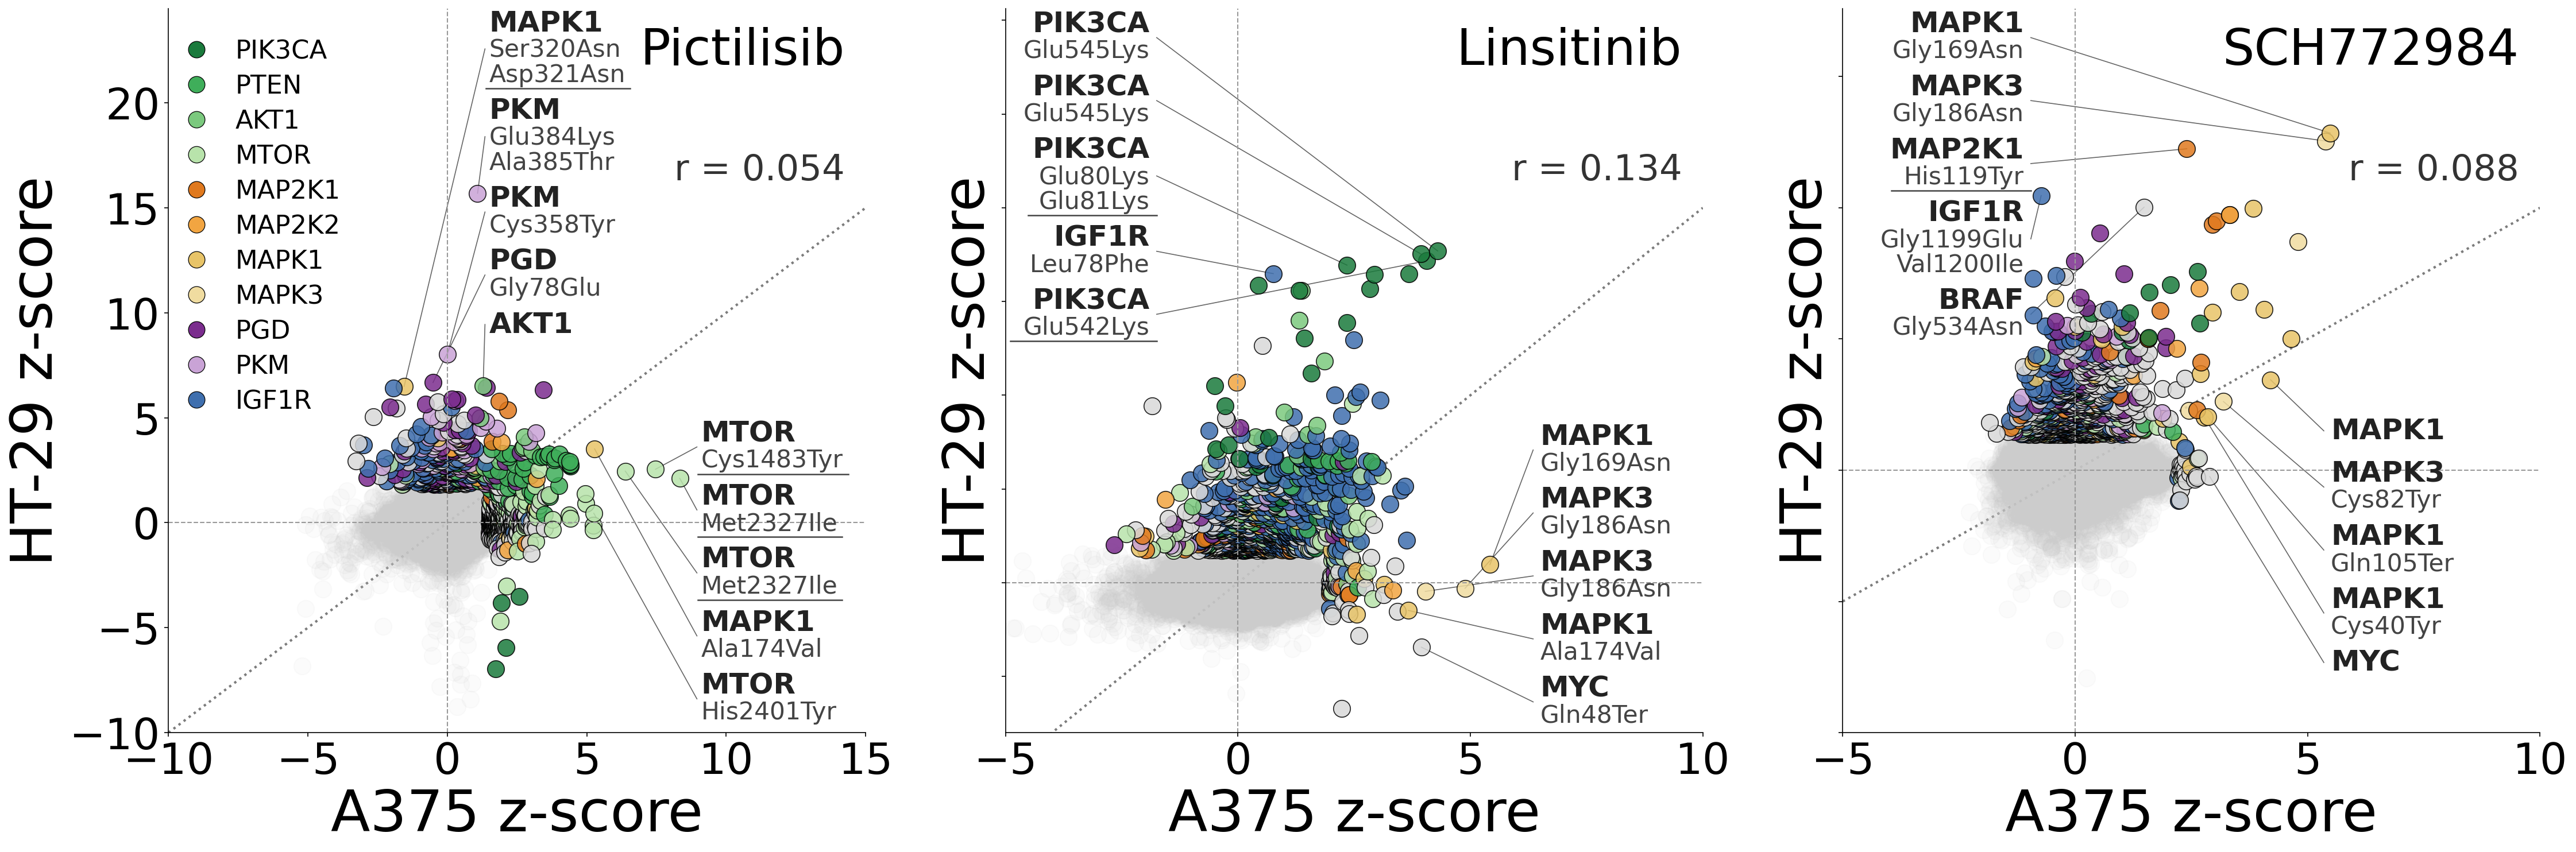

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(30, 10))

for i, (ax, drug_name) in enumerate(zip(axes, titles)):
    x_lim, y_lim, row_gap_scale = set_up_panel(ax, drug_name, show_y_labels=(i == 0))
    hits_drug = plot_points(ax, drug_name, x_lim)

    # Label the top 5 hits above and below the diagonal
    above_hits = hits_drug[hits_drug['HT29_z-score'] > hits_drug['A375_z-score']]
    below_hits = hits_drug[hits_drug['HT29_z-score'] <= hits_drug['A375_z-score']]

    for hit_type, sub_df in [('Above', above_hits), ('Below', below_hits)]:
        cfg = panel_config[drug_name][hit_type]
        top_chunk = sub_df.nlargest(5, chunk_focus[hit_type]).sort_values('HT29_z-score', ascending=False)

        reorder = label_reorderings.get((drug_name, hit_type))
        if reorder:
            top_chunk = reorder(top_chunk)

        row_records = draw_labels(ax, top_chunk, cfg, row_gap_scale)
        draw_leader_lines(fig, ax, row_records, drug_name, hit_type, cfg, x_lim, row_gap_scale)

    add_panel_text(ax, drug_name)

plt.tight_layout(w_pad=4)
add_gene_legend(axes[titles.index('Pictilisib')])

plt.savefig(figure_dir / "plot3panels.png", dpi=800, bbox_inches="tight")
plt.show()